In [2]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys
from pathlib import Path

sys.path.append(str(Path().resolve().parent / "src"))

from model_sampler import DDIMSampler
import matplotlib.pyplot as plt

from results import ModelResults, ModelComparison, build_dataset, combine_model_comparisons

## Training with different T

In [6]:
dataset = build_dataset()
ddpm1000_results = ModelResults('024-baseline-1', 'ddpm-1000', epoch=99, dataset_split='test', dataset=dataset)
ddpm2000_results = ModelResults('030-t-2000', 'ddpm-2000', epoch=149, dataset_split='test', dataset=dataset)
ddpm500_results = ModelResults('031-t-500', 'ddpm-500', epoch=99, dataset_split='test', dataset=dataset)
ddpm100_results = ModelResults('032-t-100', 'ddpm-100', epoch=99, dataset_split='test', dataset=dataset)
ddpm50_results = ModelResults('033-t-50', 'ddpm-50', epoch=99, dataset_split='test', dataset=dataset)
ddpm10_results = ModelResults('034-t-10', 'ddpm-10', epoch=99, dataset_split='test', dataset=dataset)
ddpm5_results = ModelResults('035-t-5', 'ddpm-5', epoch=99, dataset_split='test', dataset=dataset)
ddpm1_results = ModelResults('036-t-1', 'ddpm-1', epoch=99, dataset_split='test', dataset=dataset)

training_comparison = ModelComparison(
  [
    ddpm2000_results,
    ddpm1000_results,
    ddpm500_results,
    ddpm100_results,
    ddpm50_results,
    ddpm10_results,
    ddpm5_results,
    ddpm1_results,
  ],
  [
    'T=2000',
    'T=1000',
    'T=500',
    'T=100',
    'T=50',
    'T=10',
    'T=5',
    'T=1',
  ]
)

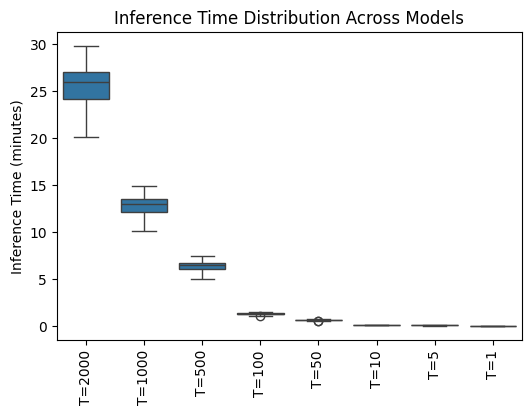

In [7]:
ax = training_comparison.plot_inference_times()
# _ = ax.set_yscale('log')

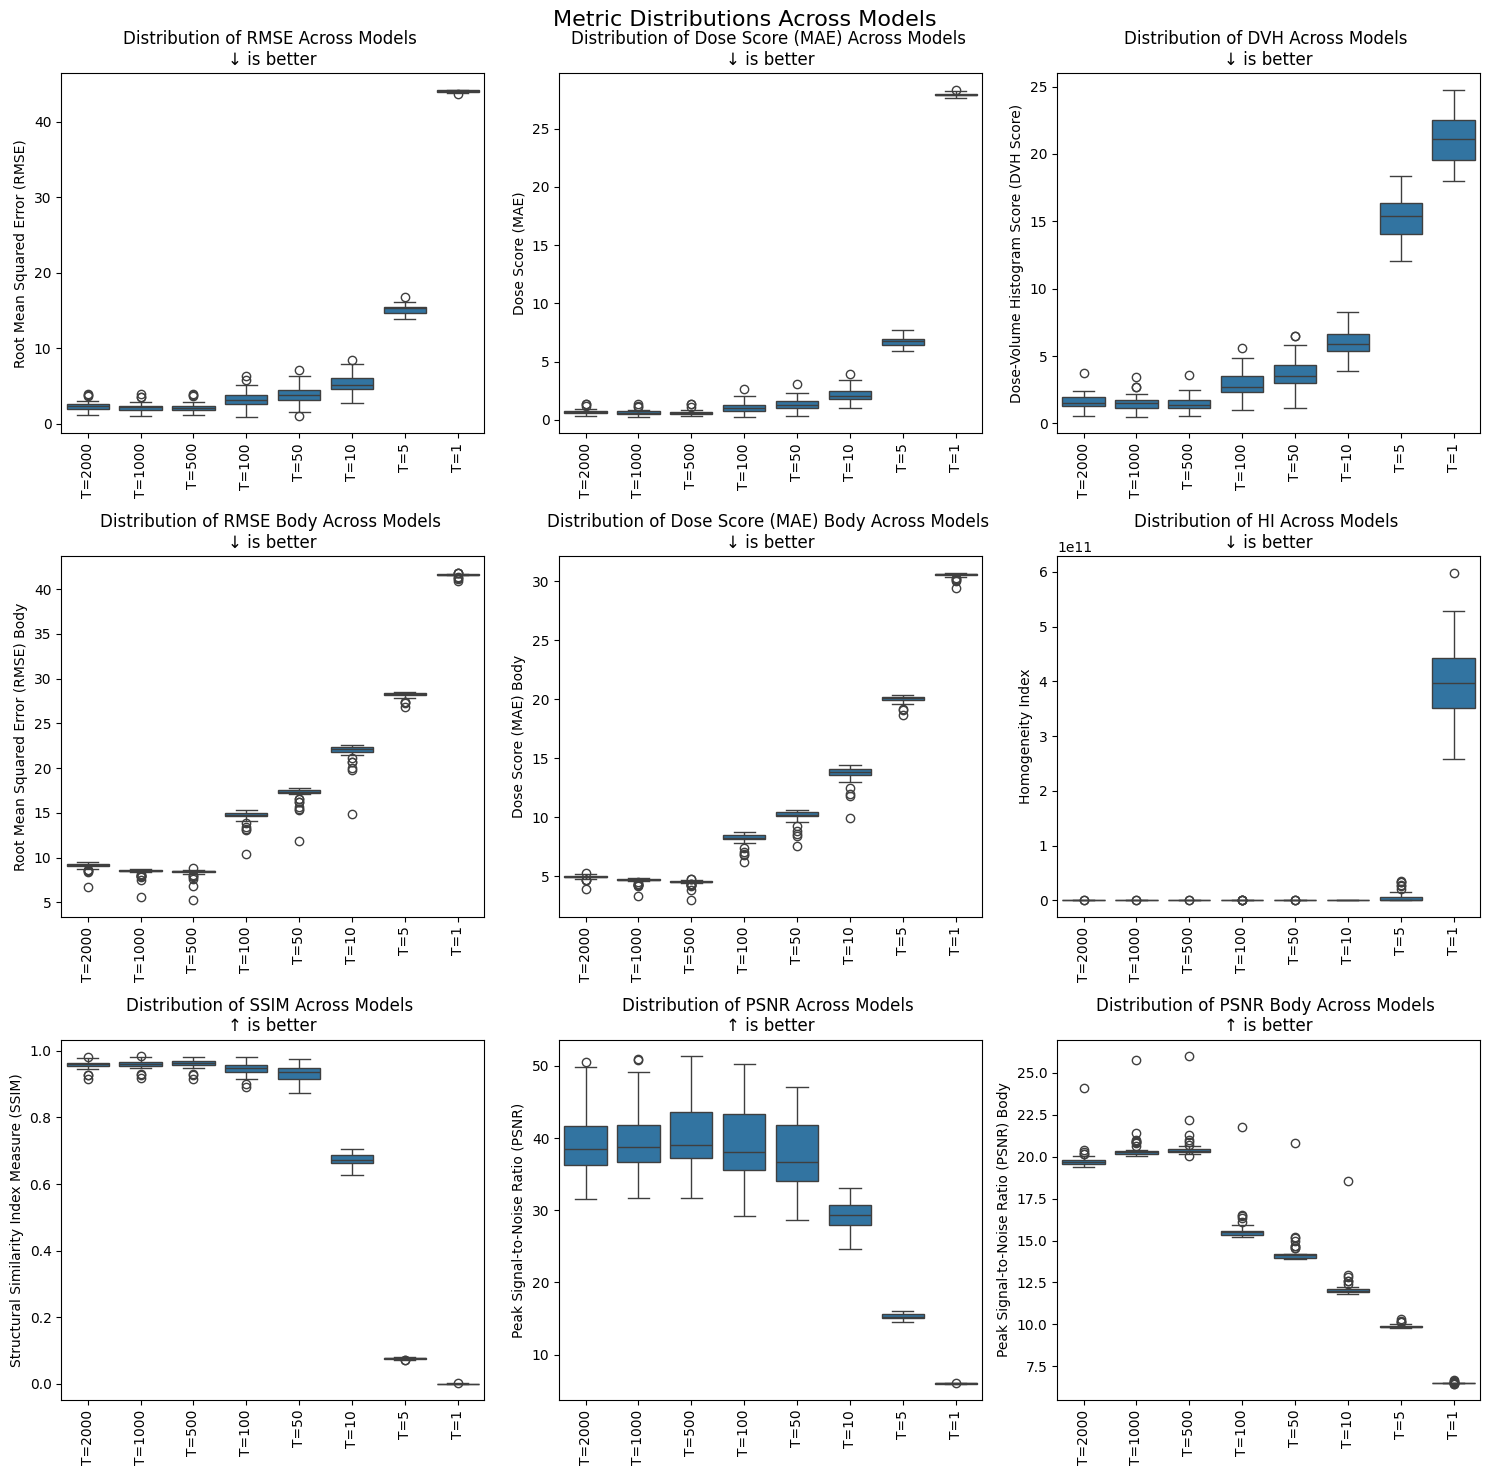

In [8]:
ax = training_comparison.plot_metric_distributions()

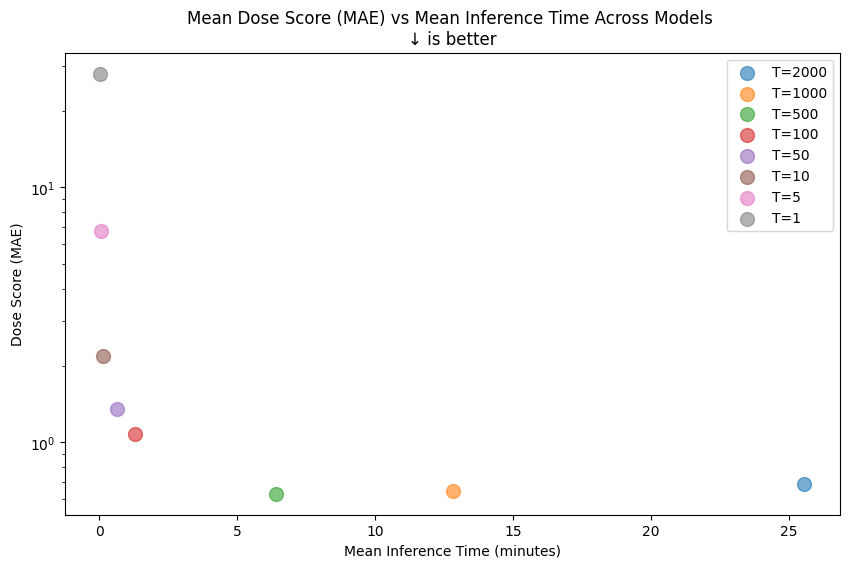

In [9]:
ax = training_comparison.plot_quality_over_time('dose_score')
_ = ax.set_yscale('log')

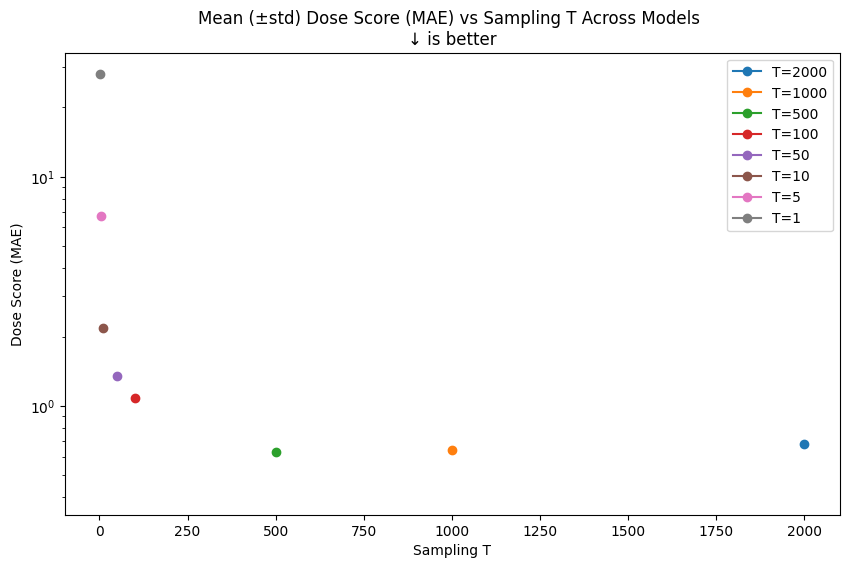

In [10]:
ax = training_comparison.plot_quality_over_T('dose_score')
_ = ax.set_yscale('log')

## Sampling with different T (T=1000 for training)

In [11]:
ddpm2000_s_results = ModelResults('024-baseline-1', 'ddpm-2000', epoch=99, dataset_split='test', dataset=dataset)
ddpm1000_s_results = ddpm1000_results
ddpm500_s_results = ModelResults('024-baseline-1', 'ddpm-500', epoch=99, dataset_split='test', dataset=dataset)
ddpm100_s_results = ModelResults('024-baseline-1', 'ddpm-100', epoch=99, dataset_split='test', dataset=dataset)
ddpm50_s_results = ModelResults('024-baseline-1', 'ddpm-50', epoch=99, dataset_split='test', dataset=dataset)
ddpm40_s_results = ModelResults('024-baseline-1', 'ddpm-40', epoch=99, dataset_split='test', dataset=dataset)
ddpm30_s_results = ModelResults('024-baseline-1', 'ddpm-30', epoch=99, dataset_split='test', dataset=dataset)
ddpm20_s_results = ModelResults('024-baseline-1', 'ddpm-20', epoch=99, dataset_split='test', dataset=dataset)
ddpm10_s_results = ModelResults('024-baseline-1', 'ddpm-10', epoch=99, dataset_split='test', dataset=dataset)
ddpm5_s_results = ModelResults('024-baseline-1', 'ddpm-5', epoch=99, dataset_split='test', dataset=dataset)
ddpm1_s_results = ModelResults('024-baseline-1', 'ddpm-1', epoch=99, dataset_split='test', dataset=dataset)

sampling_ddpm_comparision = ModelComparison(
  [
    ddpm2000_s_results,
    ddpm1000_s_results,
    ddpm500_s_results,
    ddpm100_s_results,
    ddpm50_s_results,
    ddpm40_s_results,
    ddpm30_s_results,
    ddpm20_s_results,
    ddpm10_s_results,
    ddpm5_s_results,
    ddpm1_s_results,
  ],
  [
    'T=2000',
    'T=1000',
    'T=500',
    'T=100',
    'T=50',
    'T=40',
    'T=30',
    'T=20',
    'T=10',
    'T=5',
    'T=1',
  ]
)

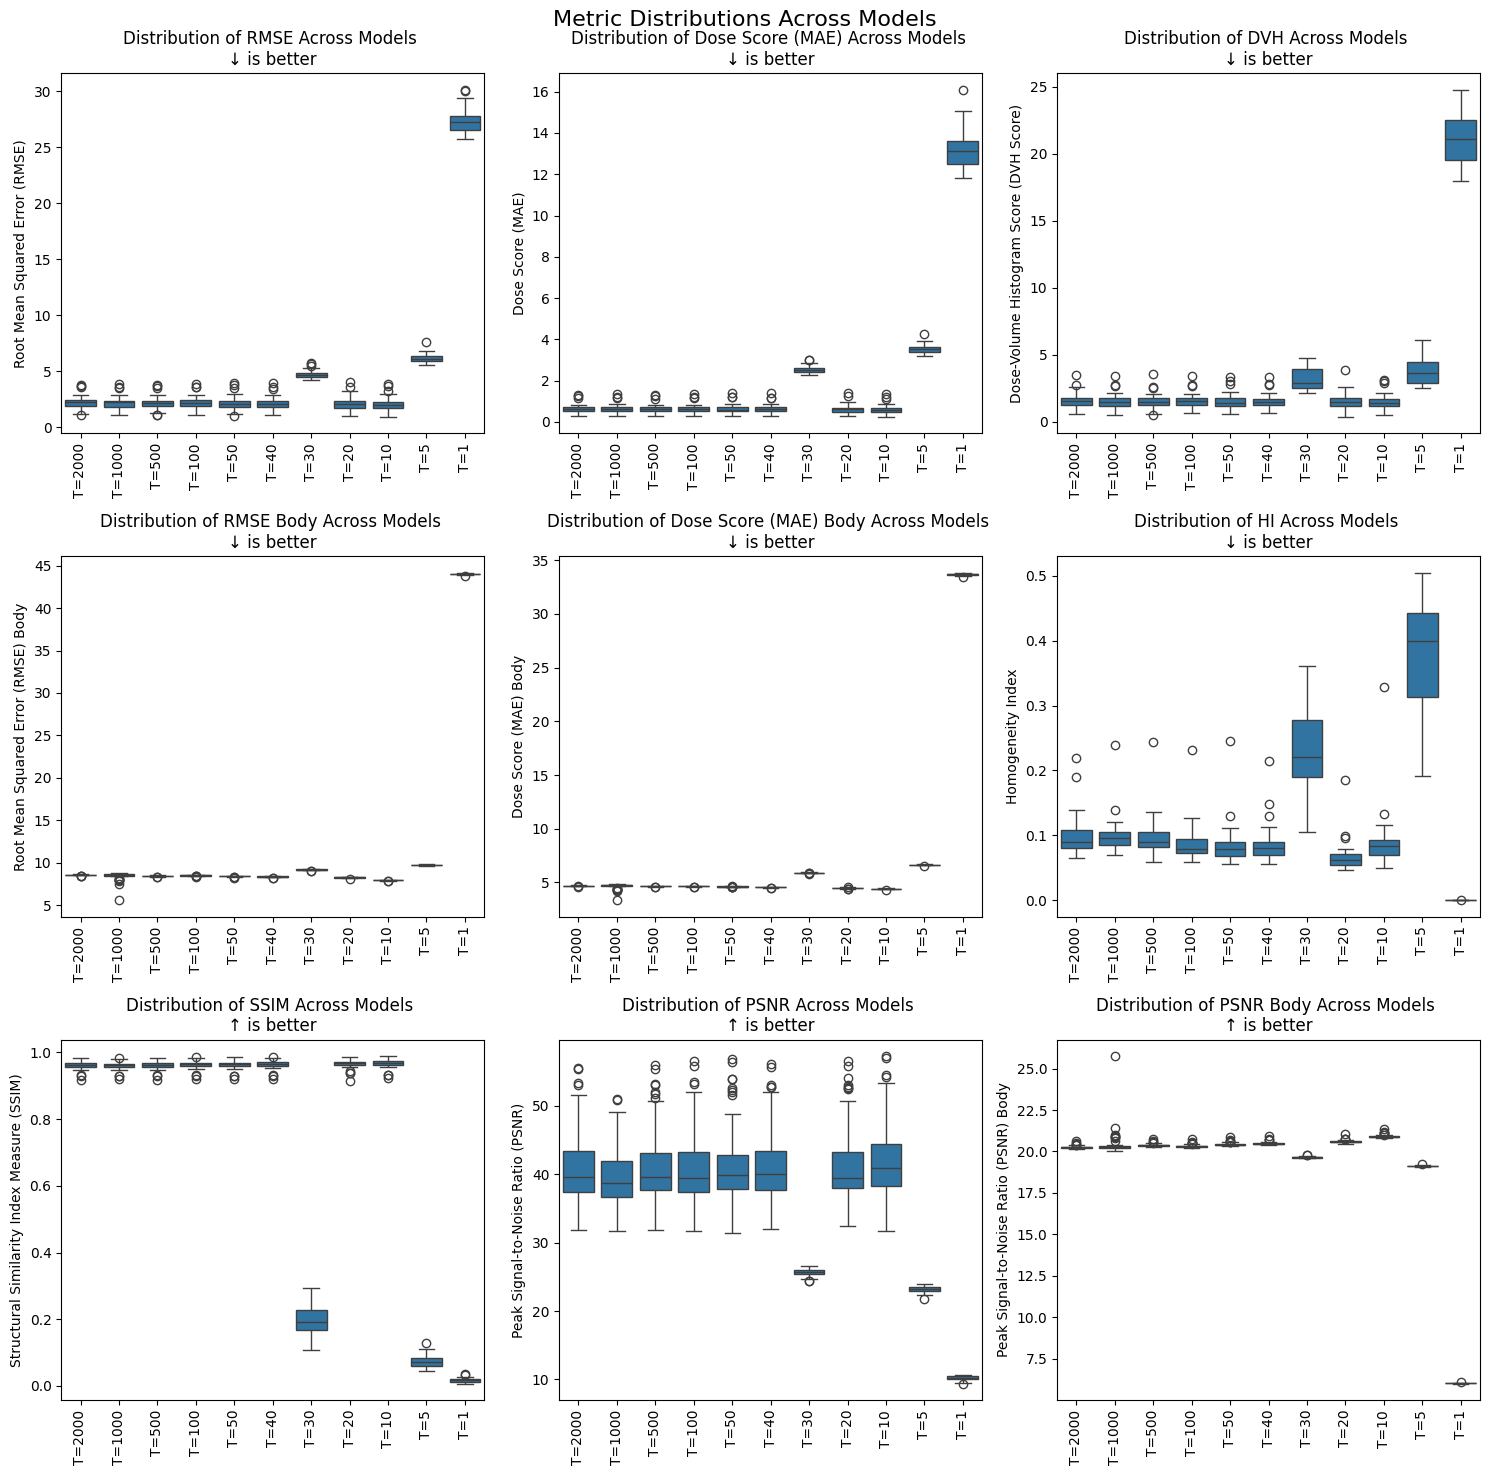

In [12]:
ax = sampling_ddpm_comparision.plot_metric_distributions()

In [13]:
training_vs_sampling_comparison = combine_model_comparisons([
  training_comparison,
  sampling_ddpm_comparision,
], [
  'Training',
  'Sampling',
])

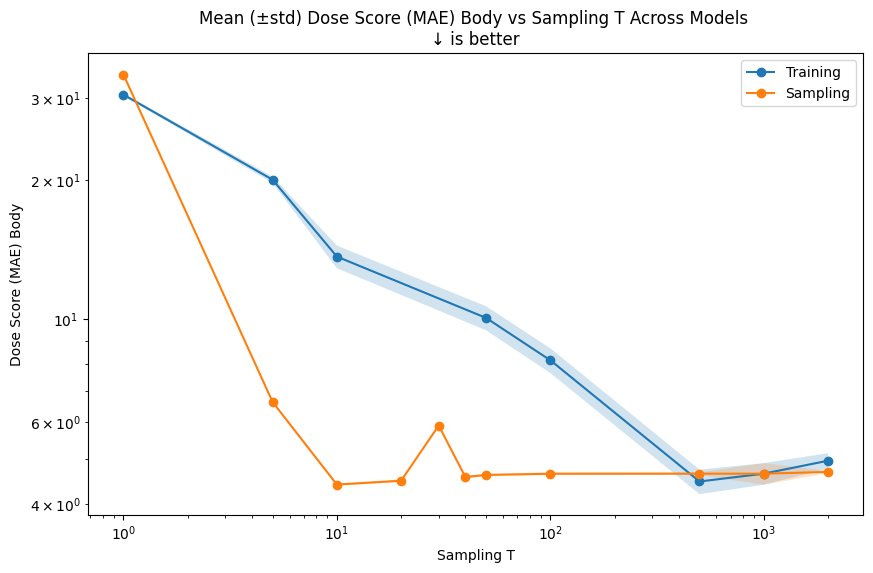

In [14]:
ax = training_vs_sampling_comparison.plot_quality_over_T('dose_score_body')
_ = ax.set_xscale('log')
_ = ax.set_yscale('log')

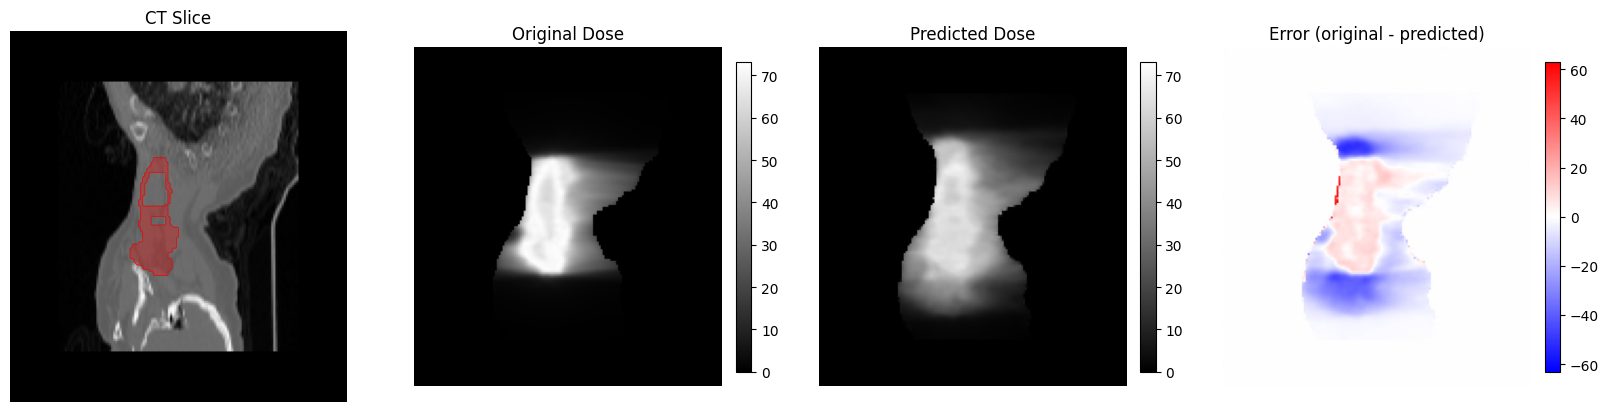

In [15]:
ax = ddpm1000_s_results.for_sample('HN-CHUM-003+S2A4Ac+MOS_20285').visualise_slice(slice_index=80)

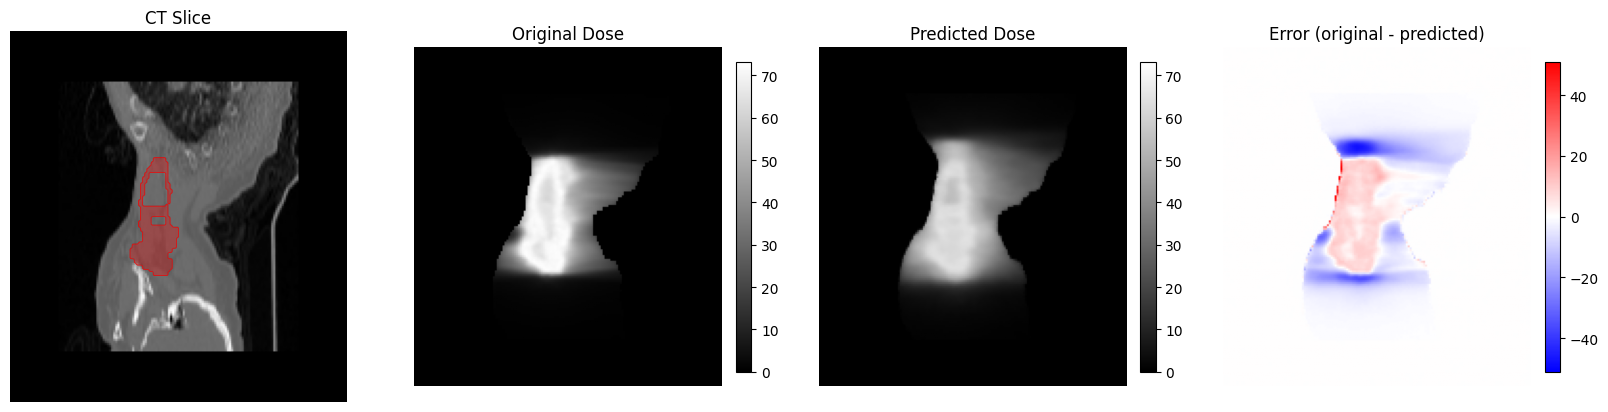

In [16]:
ax = ddpm10_s_results.for_sample('HN-CHUM-003+S2A4Ac+MOS_20285').visualise_slice(slice_index=80)

## DDIM

In [17]:
ddim1000_results = ModelResults('024-baseline-1', 'ddim-1000', epoch=99, dataset_split='test', dataset=dataset)
ddim500_results = ModelResults('024-baseline-1', 'ddim-500', epoch=99, dataset_split='test', dataset=dataset)
ddim100_results = ModelResults('024-baseline-1', 'ddim-100', epoch=99, dataset_split='test', dataset=dataset)
ddim50_results = ModelResults('024-baseline-1', 'ddim-50', epoch=99, dataset_split='test', dataset=dataset)
ddim40_results = ModelResults('024-baseline-1', 'ddim-40', epoch=99, dataset_split='test', dataset=dataset)
ddim30_results = ModelResults('024-baseline-1', 'ddim-30', epoch=99, dataset_split='test', dataset=dataset)
ddim20_results = ModelResults('024-baseline-1', 'ddim-20', epoch=99, dataset_split='test', dataset=dataset)
ddim10_results = ModelResults('024-baseline-1', 'ddim-10', epoch=99, dataset_split='test', dataset=dataset)
ddim5_results = ModelResults('024-baseline-1', 'ddim-5', epoch=99, dataset_split='test', dataset=dataset)
ddim1_results = ModelResults('024-baseline-1', 'ddim-1', epoch=99, dataset_split='test', dataset=dataset)

ddim_comparison = ModelComparison(
  [
    ddim1000_results,
    ddim500_results,
    ddim100_results,
    ddim50_results,
    ddim40_results,
    ddim30_results,
    ddim20_results,
    ddim10_results,
    ddim5_results,
    ddim1_results,
  ],
  [
    'T=1000',
    'T=500',
    'T=100',
    'T=50',
    'T=40',
    'T=30',
    'T=20',
    'T=10',
    'T=5',
    'T=1',
  ]
)

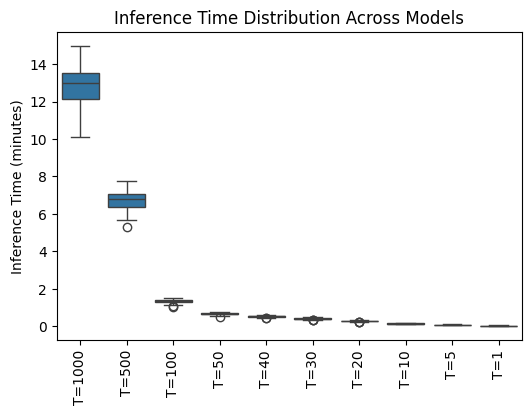

In [18]:
ax = ddim_comparison.plot_inference_times()


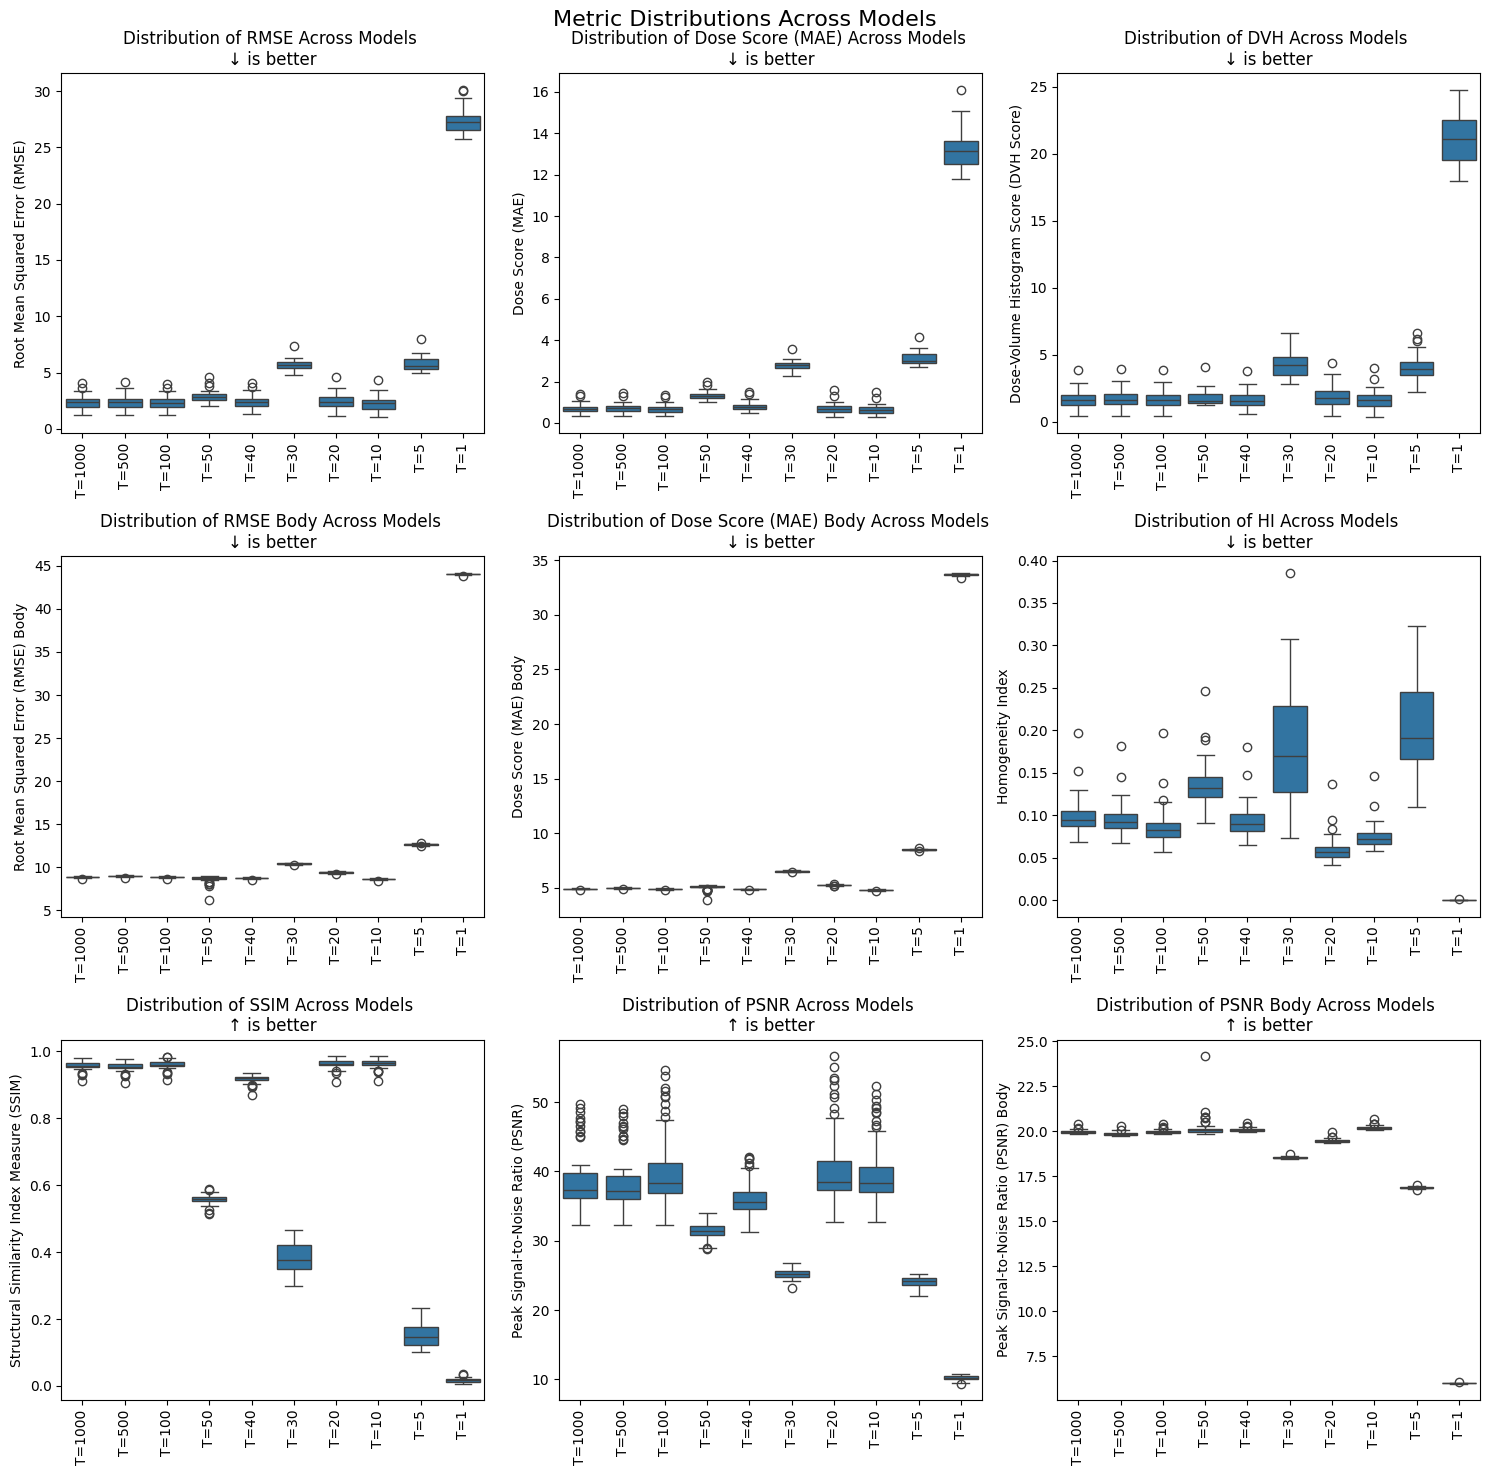

In [19]:
ax = ddim_comparison.plot_metric_distributions()

In [20]:
ddpm_ddim_comparison = combine_model_comparisons([
  sampling_ddpm_comparision,
  ddim_comparison,
], [
  'DDPM Sampling',
  'DDIM Sampling',
])

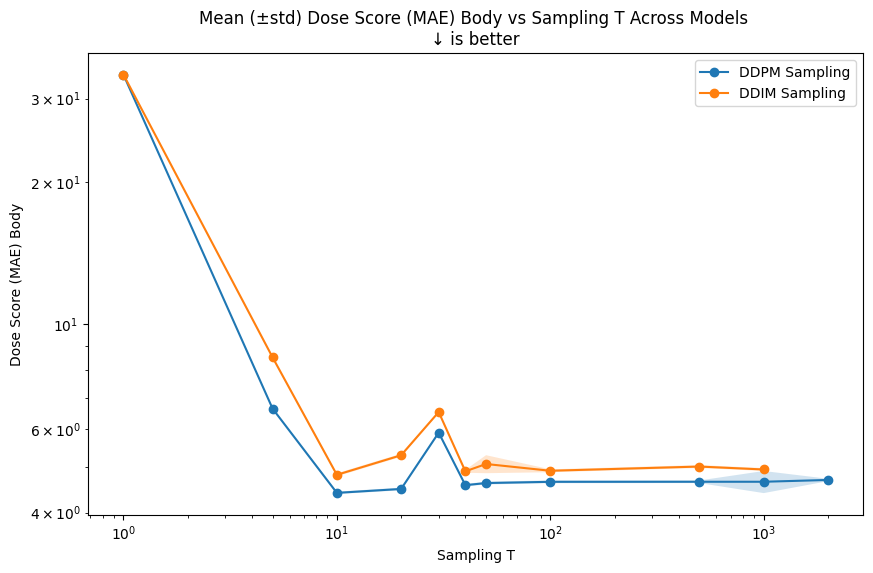

In [21]:
ax = ddpm_ddim_comparison.plot_quality_over_T('dose_score_body')
_ = ax.set_xscale('log')
_ = ax.set_yscale('log')

Text(0, 0.5, 'Timestep')

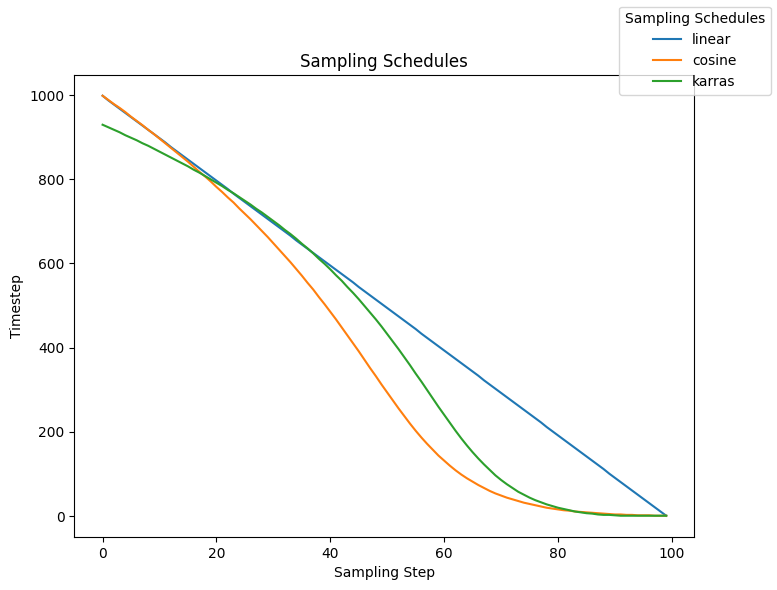

In [22]:
linear_sampler = DDIMSampler(None, 0.0001, 0.02, 1000, None, 100, 0, 'linear')
cosine_sampler = DDIMSampler(None, 0.0001, 0.02, 1000, None, 100, 0, 'cosine')
karras_sampler = DDIMSampler(None, 0.0001, 0.02, 1000, None, 100, 0, 'karras')

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(linear_sampler.sampling_indices, label='linear')
ax.plot(cosine_sampler.sampling_indices, label='cosine')
ax.plot(karras_sampler.sampling_indices, label='karras')
fig.legend(title='Sampling Schedules', loc='upper right')
ax.set_title('Sampling Schedules')
ax.set_xlabel('Sampling Step')
ax.set_ylabel('Timestep')


## DDIM Cosine

In [23]:
ddim1000cos_results = ModelResults('024-baseline-1', 'ddim-cosine-1000', epoch=99, dataset_split='test', dataset=dataset)
ddim500cos_results = ModelResults('024-baseline-1', 'ddim-cosine-500', epoch=99, dataset_split='test', dataset=dataset)
ddim100cos_results = ModelResults('024-baseline-1', 'ddim-cosine-100', epoch=99, dataset_split='test', dataset=dataset)
ddim50cos_results = ModelResults('024-baseline-1', 'ddim-cosine-50', epoch=99, dataset_split='test', dataset=dataset)
ddim40cos_results = ModelResults('024-baseline-1', 'ddim-cosine-40', epoch=99, dataset_split='test', dataset=dataset)
ddim30cos_results = ModelResults('024-baseline-1', 'ddim-cosine-30', epoch=99, dataset_split='test', dataset=dataset)
ddim20cos_results = ModelResults('024-baseline-1', 'ddim-cosine-20', epoch=99, dataset_split='test', dataset=dataset)
ddim10cos_results = ModelResults('024-baseline-1', 'ddim-cosine-10', epoch=99, dataset_split='test', dataset=dataset)
ddim5cos_results = ModelResults('024-baseline-1', 'ddim-cosine-5', epoch=99, dataset_split='test', dataset=dataset)
ddim1cos_results = ModelResults('024-baseline-1', 'ddim-cosine-1', epoch=99, dataset_split='test', dataset=dataset)

ddim_cosine_comparison = ModelComparison(
  [
    ddim1000cos_results,
    ddim500cos_results,
    ddim100cos_results,
    ddim50cos_results,
    ddim40cos_results,
    ddim30cos_results,
    ddim20cos_results,
    ddim10cos_results,
    ddim5cos_results,
    ddim1cos_results,
  ],
  [
    'T=1000',
    'T=500',
    'T=100',
    'T=50',
    'T=40',
    'T=30',
    'T=20',
    'T=10',
    'T=5',
    'T=1',
  ]
)


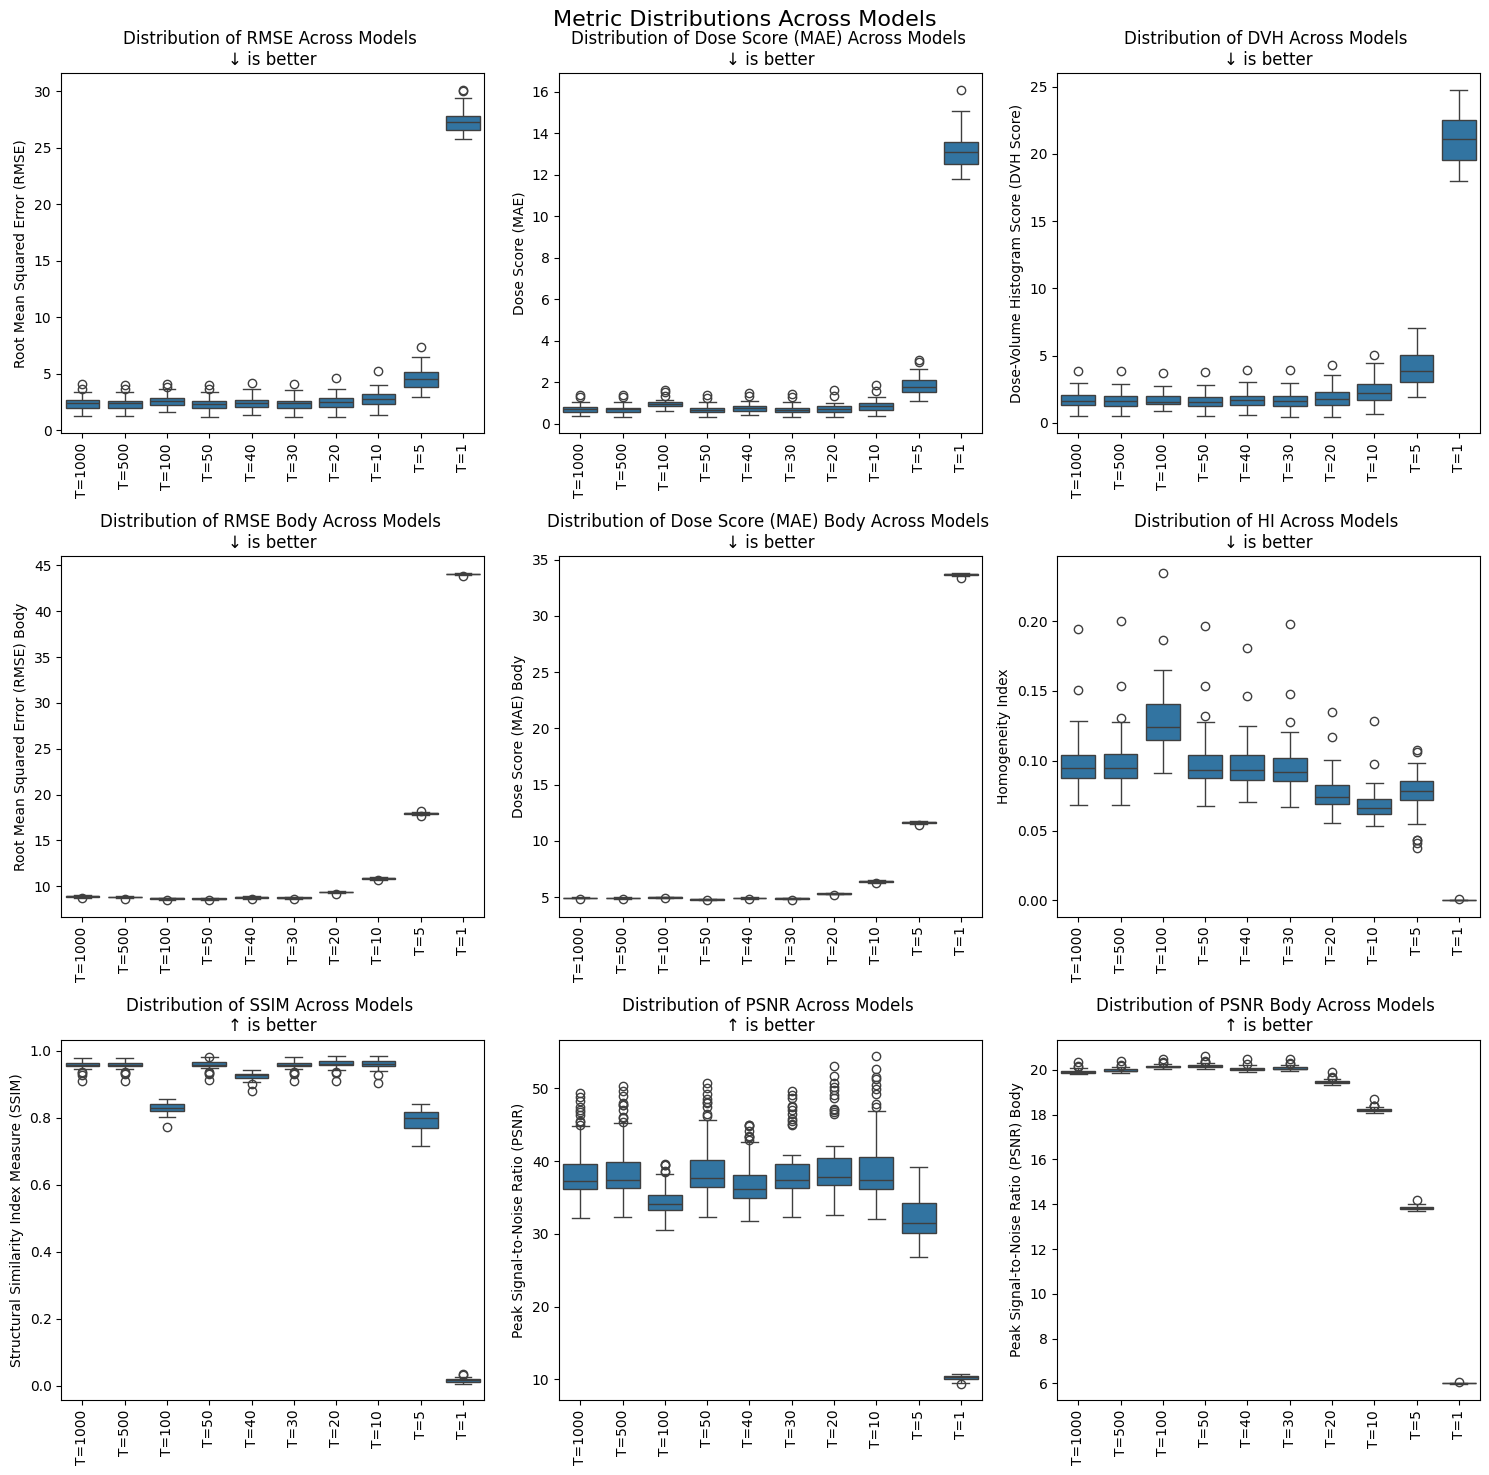

In [24]:
ax = ddim_cosine_comparison.plot_metric_distributions()

## DDIM Karras

In [25]:
ddim1000karras_results = ModelResults('024-baseline-1', 'ddim-karras-1000', epoch=99, dataset_split='test', dataset=dataset)
ddim500karras_results = ModelResults('024-baseline-1', 'ddim-karras-500', epoch=99, dataset_split='test', dataset=dataset)
ddim100karras_results = ModelResults('024-baseline-1', 'ddim-karras-100', epoch=99, dataset_split='test', dataset=dataset)
ddim50karras_results = ModelResults('024-baseline-1', 'ddim-karras-50', epoch=99, dataset_split='test', dataset=dataset)
ddim40karras_results = ModelResults('024-baseline-1', 'ddim-karras-40', epoch=99, dataset_split='test', dataset=dataset)
ddim30karras_results = ModelResults('024-baseline-1', 'ddim-karras-30', epoch=99, dataset_split='test', dataset=dataset)
ddim20karras_results = ModelResults('024-baseline-1', 'ddim-karras-20', epoch=99, dataset_split='test', dataset=dataset)
ddim10karras_results = ModelResults('024-baseline-1', 'ddim-karras-10', epoch=99, dataset_split='test', dataset=dataset)
ddim5karras_results = ModelResults('024-baseline-1', 'ddim-karras-5', epoch=99, dataset_split='test', dataset=dataset)
ddim1karras_results = ModelResults('024-baseline-1', 'ddim-karras-1', epoch=99, dataset_split='test', dataset=dataset)

ddim_karras_comparison = ModelComparison(
  [
    ddim1000karras_results,
    ddim500karras_results,
    ddim100karras_results,
    ddim50karras_results,
    ddim40karras_results,
    ddim30karras_results,
    ddim20karras_results,
    ddim10karras_results,
    ddim5karras_results,
    ddim1karras_results,
  ],
  [
    'T=1000',
    'T=500',
    'T=100',
    'T=50',
    'T=40',
    'T=30',
    'T=20',
    'T=10',
    'T=5',
    'T=1',
  ]
)

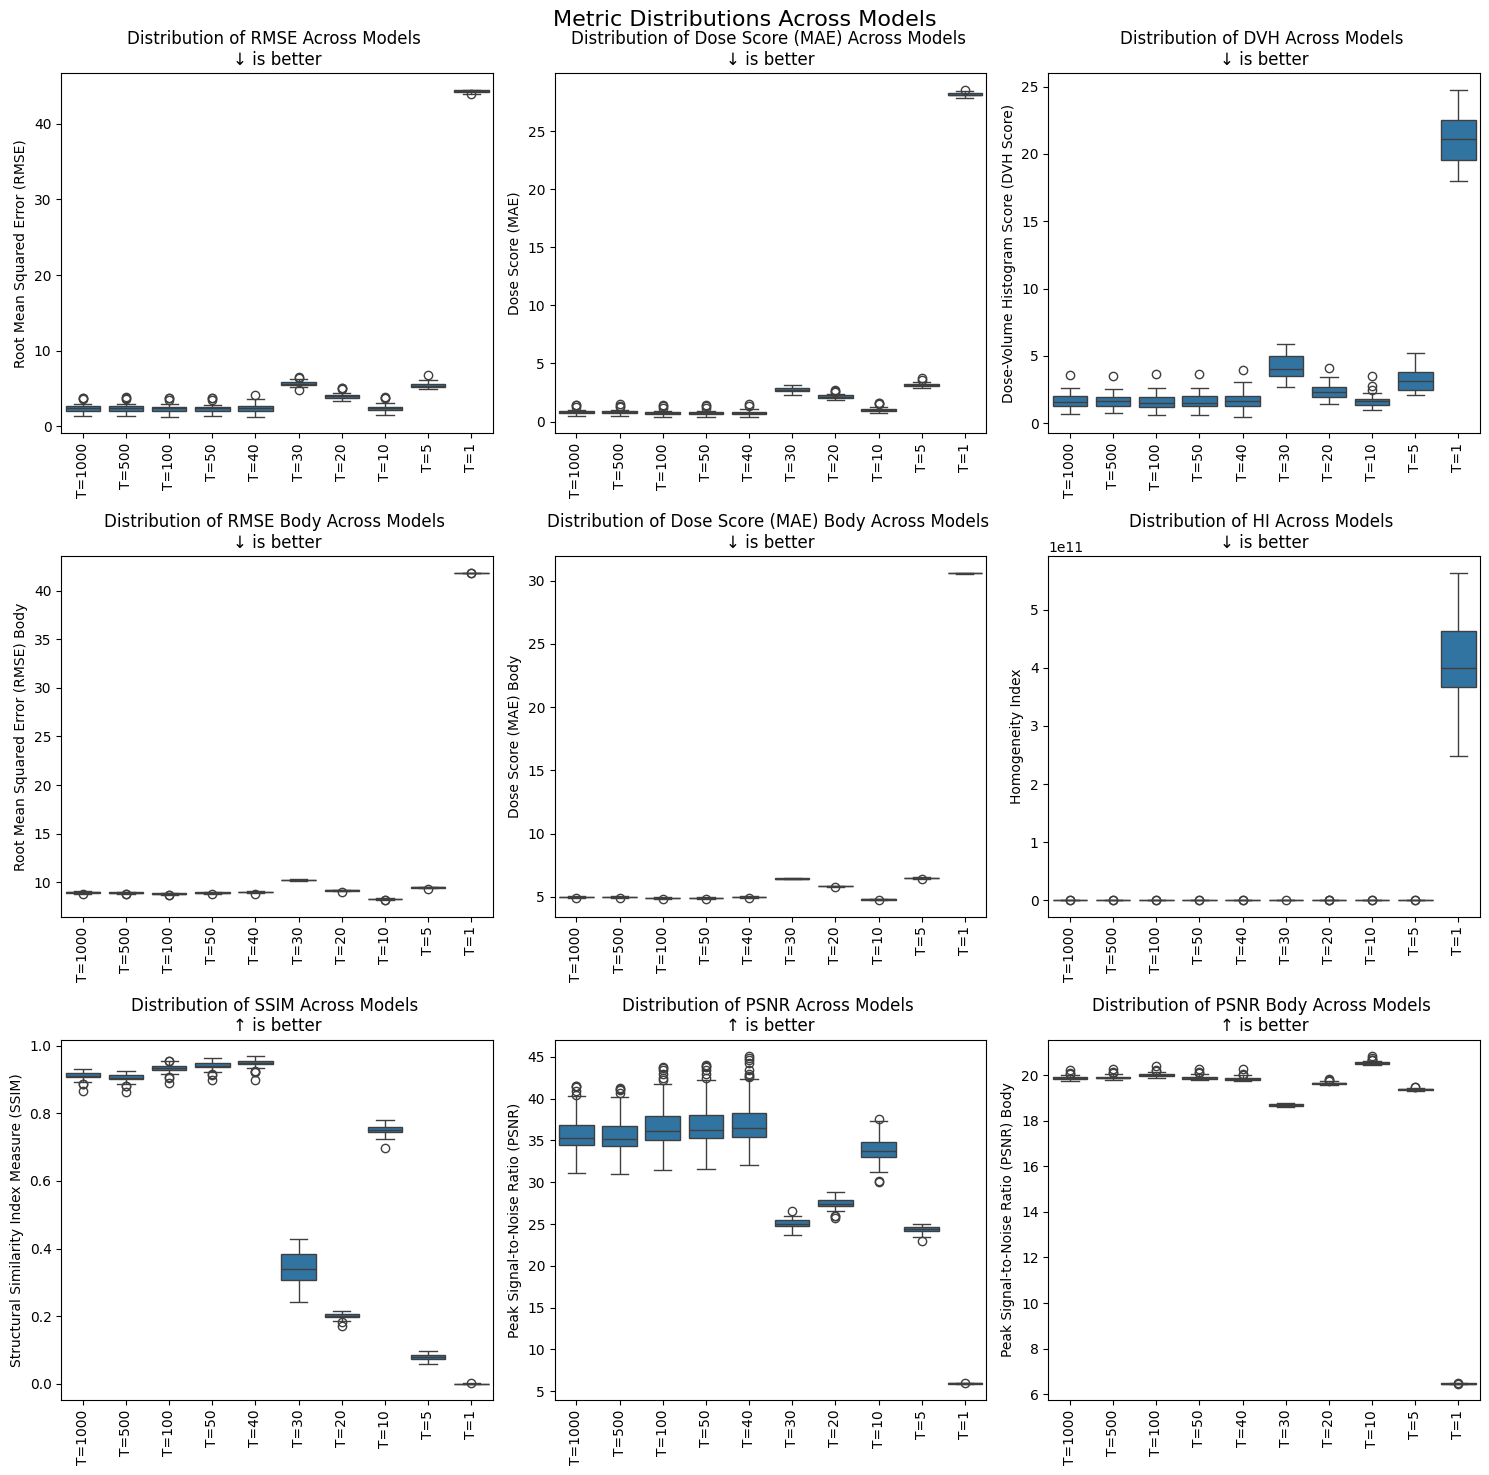

In [26]:
ax = ddim_karras_comparison.plot_metric_distributions()

In [27]:
ddim_schedules_comparison = combine_model_comparisons([
  ddim_comparison,
  ddim_cosine_comparison,
  ddim_karras_comparison,
], [
  'DDIM Linear',
  'DDIM Cosine',
  'DDIM Karras',
])

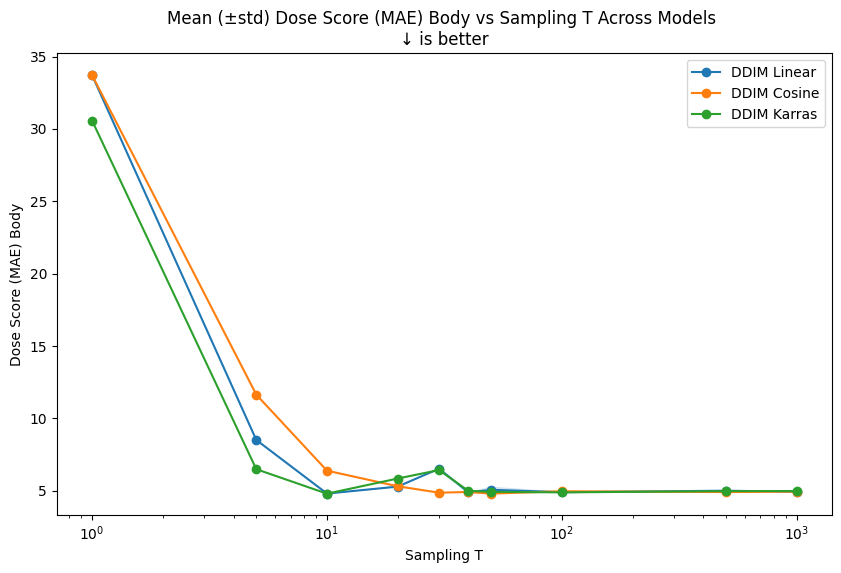

In [28]:
ax = ddim_schedules_comparison.plot_quality_over_T('dose_score_body')
_ = ax.set_xscale('log')
# _ = ax.set_yscale('log')

## DEIS

In [30]:
deis_1_1000_results = ModelResults('024-baseline-1', 'deis-1-1000', epoch=99, dataset_split='test', dataset=dataset)
deis_1_500_results = ModelResults('024-baseline-1', 'deis-1-500', epoch=99, dataset_split='test', dataset=dataset)
deis_1_100_results = ModelResults('024-baseline-1', 'deis-1-100', epoch=99, dataset_split='test', dataset=dataset)
deis_1_50_results = ModelResults('024-baseline-1', 'deis-1-50', epoch=99, dataset_split='test', dataset=dataset)
deis_1_40_results = ModelResults('024-baseline-1', 'deis-1-40', epoch=99, dataset_split='test', dataset=dataset)
deis_1_30_results = ModelResults('024-baseline-1', 'deis-1-30', epoch=99, dataset_split='test', dataset=dataset)
deis_1_20_results = ModelResults('024-baseline-1', 'deis-1-20', epoch=99, dataset_split='test', dataset=dataset)
deis_1_10_results = ModelResults('024-baseline-1', 'deis-1-10', epoch=99, dataset_split='test', dataset=dataset)
deis_1_5_results = ModelResults('024-baseline-1', 'deis-1-5', epoch=99, dataset_split='test', dataset=dataset)
deis_1_1_results = ModelResults('024-baseline-1', 'deis-1-1', epoch=99, dataset_split='test', dataset=dataset)

deis_1_comparison = ModelComparison(
  [
    deis_1_1000_results,
    deis_1_500_results,
    deis_1_100_results,
    deis_1_50_results,
    deis_1_40_results,
    deis_1_30_results,
    deis_1_20_results,
    deis_1_10_results,
    deis_1_5_results,
    deis_1_1_results,
  ],
  [
    'T=1000',
    'T=500',
    'T=100',
    'T=50',
    'T=40',
    'T=30',
    'T=20',
    'T=10',
    'T=5',
    'T=1',
  ]
)


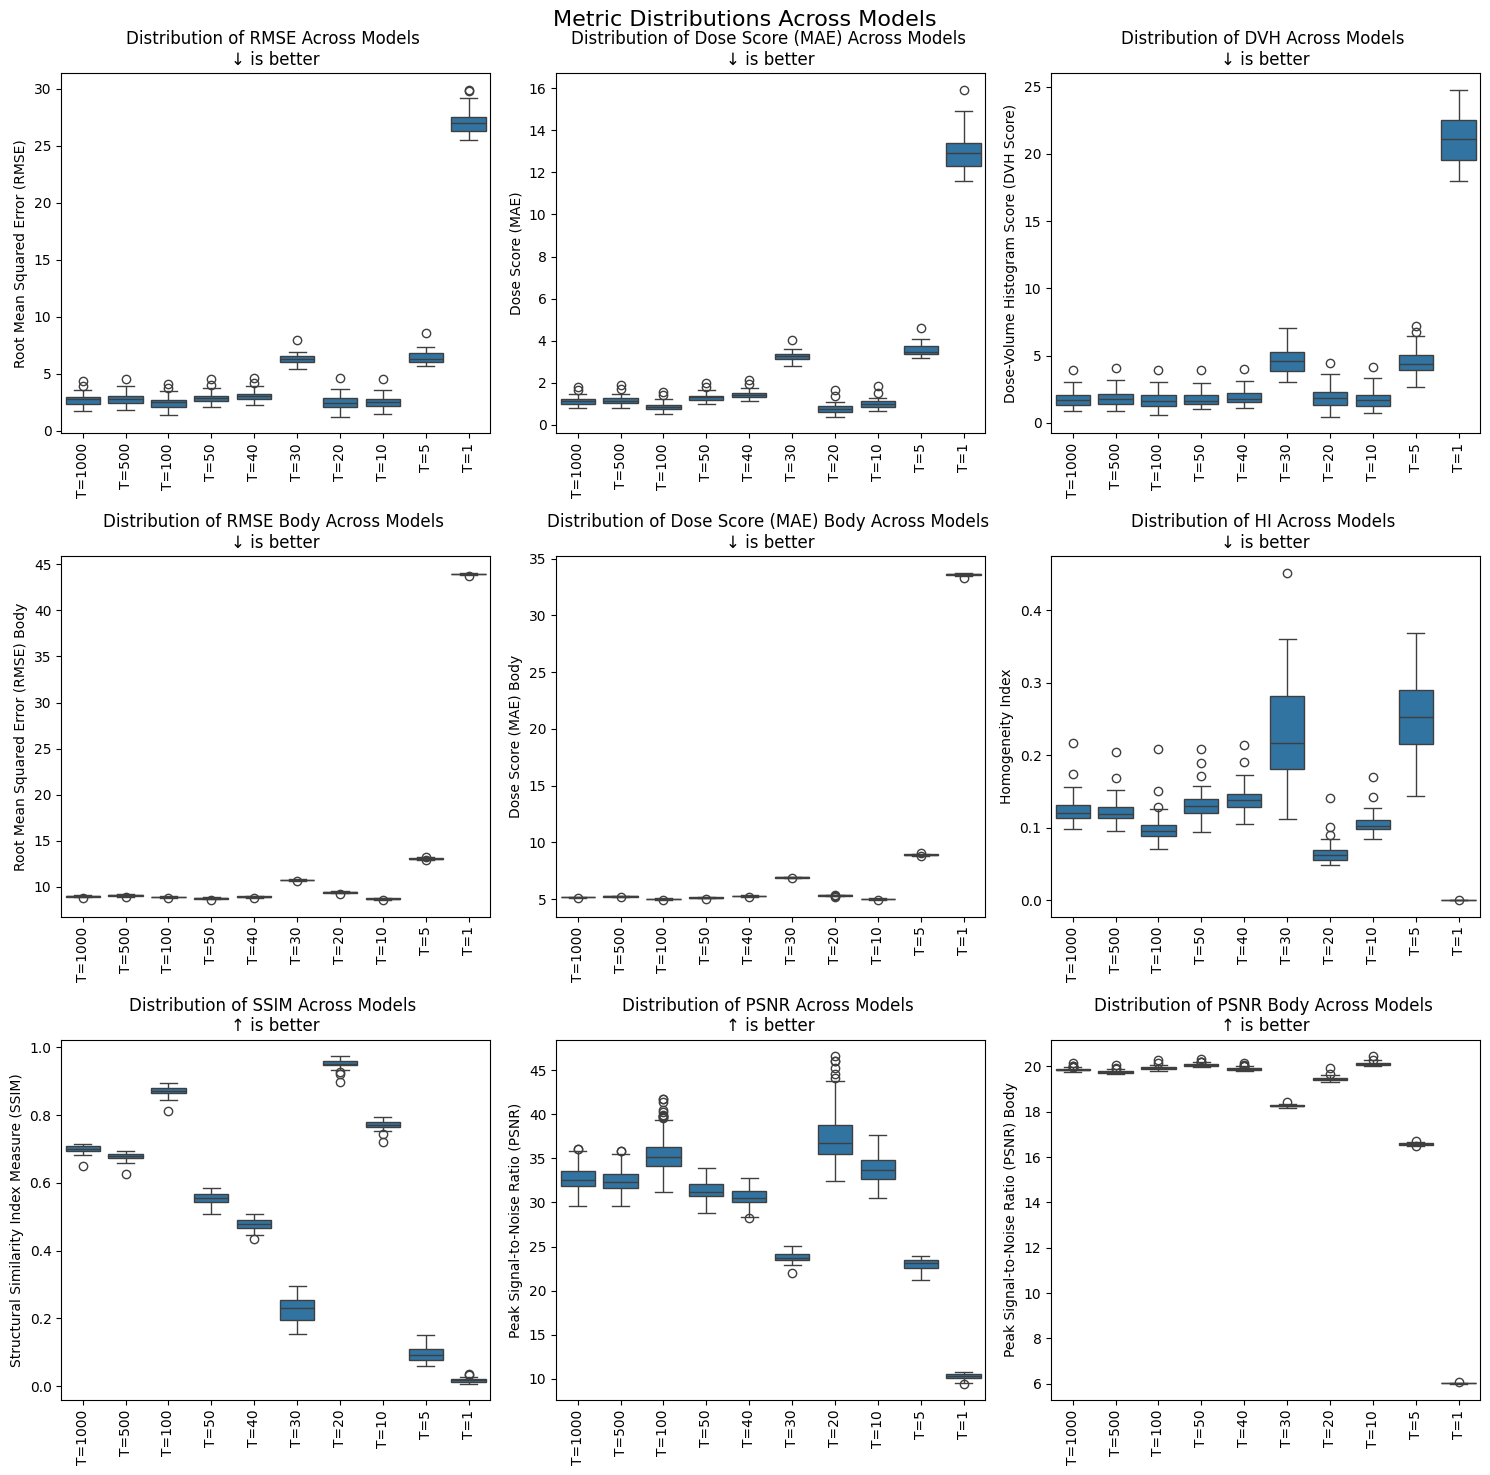

In [31]:
ax = deis_1_comparison.plot_metric_distributions()

In [35]:
deis_2_1000_results = ModelResults('024-baseline-1', 'deis-2-1000', epoch=99, dataset_split='test', dataset=dataset)
deis_2_500_results = ModelResults('024-baseline-1', 'deis-2-500', epoch=99, dataset_split='test', dataset=dataset)
deis_2_100_results = ModelResults('024-baseline-1', 'deis-2-100', epoch=99, dataset_split='test', dataset=dataset)
deis_2_50_results = ModelResults('024-baseline-1', 'deis-2-50', epoch=99, dataset_split='test', dataset=dataset)
deis_2_40_results = ModelResults('024-baseline-1', 'deis-2-40', epoch=99, dataset_split='test', dataset=dataset)
deis_2_30_results = ModelResults('024-baseline-1', 'deis-2-30', epoch=99, dataset_split='test', dataset=dataset)
deis_2_20_results = ModelResults('024-baseline-1', 'deis-2-20', epoch=99, dataset_split='test', dataset=dataset)
deis_2_10_results = ModelResults('024-baseline-1', 'deis-2-10', epoch=99, dataset_split='test', dataset=dataset)
deis_2_5_results = ModelResults('024-baseline-1', 'deis-2-5', epoch=99, dataset_split='test', dataset=dataset)
deis_2_1_results = ModelResults('024-baseline-1', 'deis-2-1', epoch=99, dataset_split='test', dataset=dataset)


deis_2_comparison = ModelComparison(
  [
    deis_2_1000_results,
    deis_2_500_results,
    deis_2_100_results,
    deis_2_50_results,
    deis_2_40_results,
    deis_2_30_results,
    deis_2_20_results,
    deis_2_10_results,
    deis_2_5_results,
    deis_2_1_results,
  ],
  [
    'T=1000',
    'T=500',
    'T=100',
    'T=50',
    'T=40',
    'T=30',
    'T=20',
    'T=10',
    'T=5',
    'T=1',
  ]
)

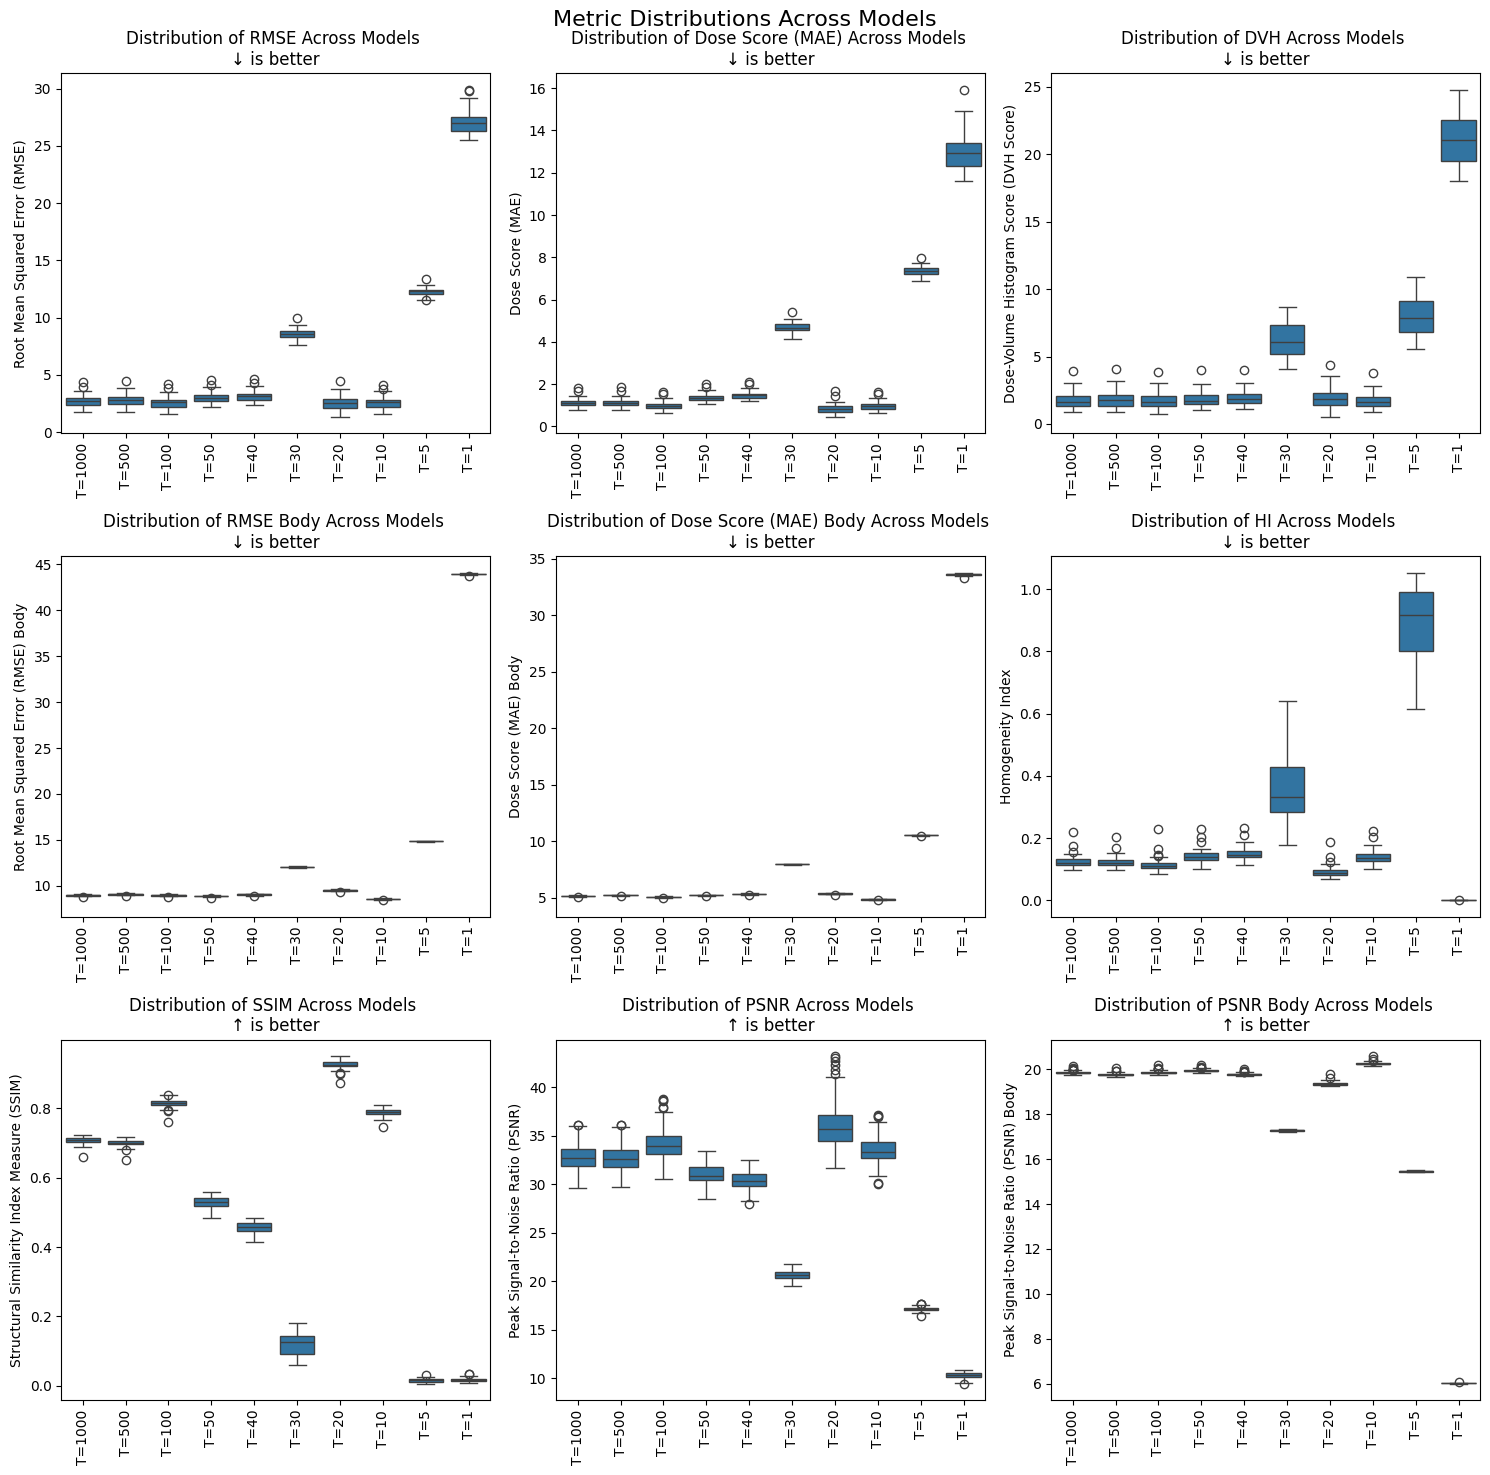

In [36]:
ax = deis_2_comparison.plot_metric_distributions()

In [39]:
deis_3_1000_results = ModelResults('024-baseline-1', 'deis-3-1000', epoch=99, dataset_split='test', dataset=dataset)
deis_3_500_results = ModelResults('024-baseline-1', 'deis-3-500', epoch=99, dataset_split='test', dataset=dataset)
deis_3_100_results = ModelResults('024-baseline-1', 'deis-3-100', epoch=99, dataset_split='test', dataset=dataset)
deis_3_50_results = ModelResults('024-baseline-1', 'deis-3-50', epoch=99, dataset_split='test', dataset=dataset)
deis_3_40_results = ModelResults('024-baseline-1', 'deis-3-40', epoch=99, dataset_split='test', dataset=dataset)
deis_3_30_results = ModelResults('024-baseline-1', 'deis-3-30', epoch=99, dataset_split='test', dataset=dataset)
deis_3_20_results = ModelResults('024-baseline-1', 'deis-3-20', epoch=99, dataset_split='test', dataset=dataset)
deis_3_10_results = ModelResults('024-baseline-1', 'deis-3-10', epoch=99, dataset_split='test', dataset=dataset)
deis_3_5_results = ModelResults('024-baseline-1', 'deis-3-5', epoch=99, dataset_split='test', dataset=dataset)
deis_3_1_results = ModelResults('024-baseline-1', 'deis-3-1', epoch=99, dataset_split='test', dataset=dataset)

deis_3_comparison = ModelComparison(
  [
    deis_3_1000_results,
    deis_3_500_results,
    deis_3_100_results,
    deis_3_50_results,
    deis_3_40_results,
    deis_3_30_results,
    deis_3_20_results,
    deis_3_10_results,
    deis_3_5_results,
    deis_3_1_results,
  ],
  [
    'T=1000',
    'T=500',
    'T=100',
    'T=50',
    'T=40',
    'T=30',
    'T=20',
    'T=10',
    'T=5',
    'T=1',
  ]
)

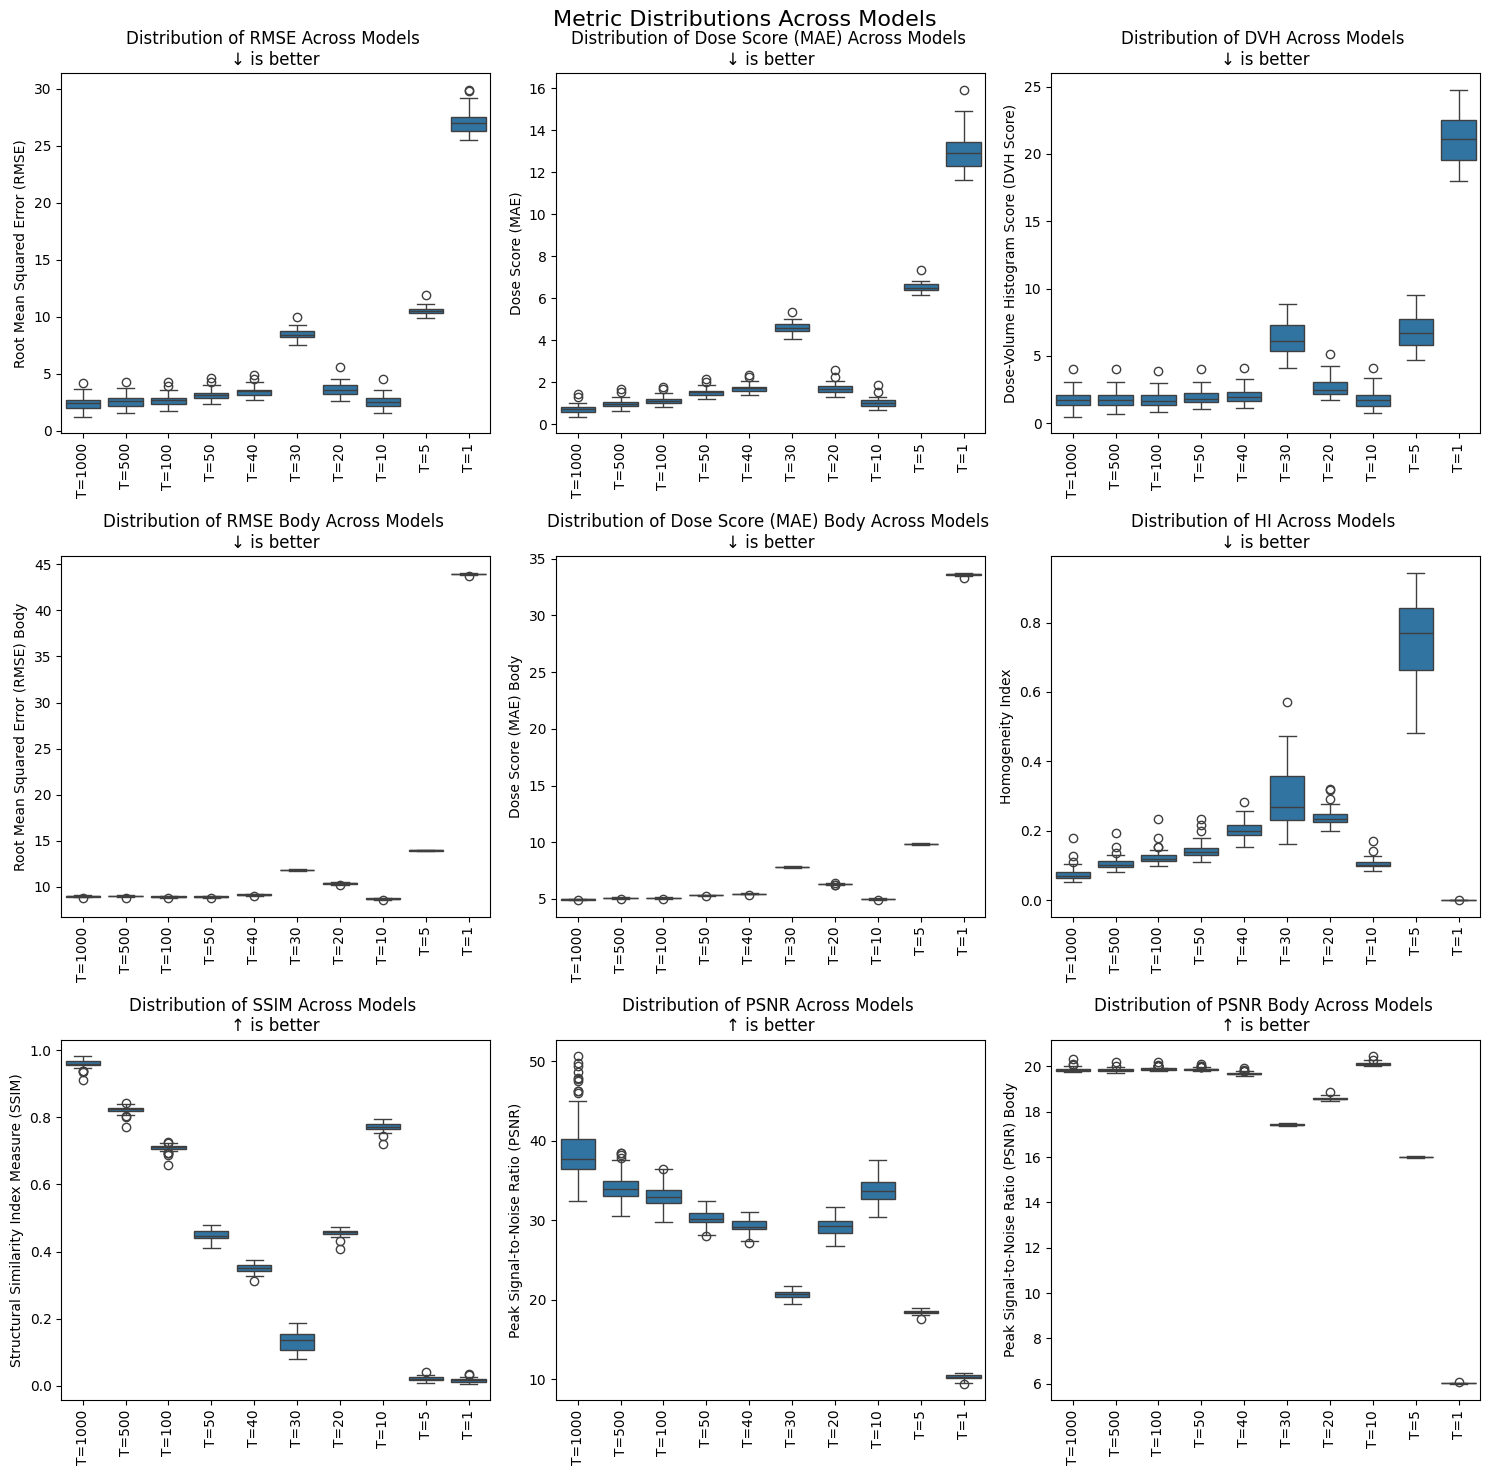

In [40]:
ax = deis_3_comparison.plot_metric_distributions()

In [43]:
deis_comparison = combine_model_comparisons([
  deis_1_comparison,
  deis_2_comparison,
  deis_3_comparison,
], [
  'DEIS o=1',
  'DEIS o=2',
  'DEIS o=3',
])

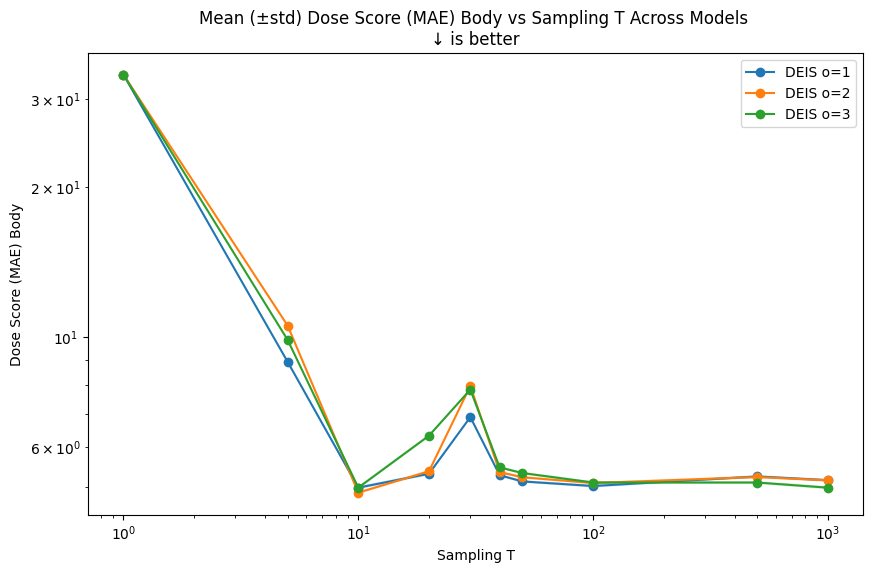

In [44]:
ax = deis_comparison.plot_quality_over_T('dose_score_body')
_ = ax.set_xscale('log')
_ = ax.set_yscale('log')

## General Comparisons

In [45]:
general_comparison = combine_model_comparisons(
  [
    sampling_ddpm_comparision,
    ddim_comparison,
    deis_1_comparison,
  ],
  [
    'DDPM',
    'DDIM',
    'DEIS o=1',
  ]
)

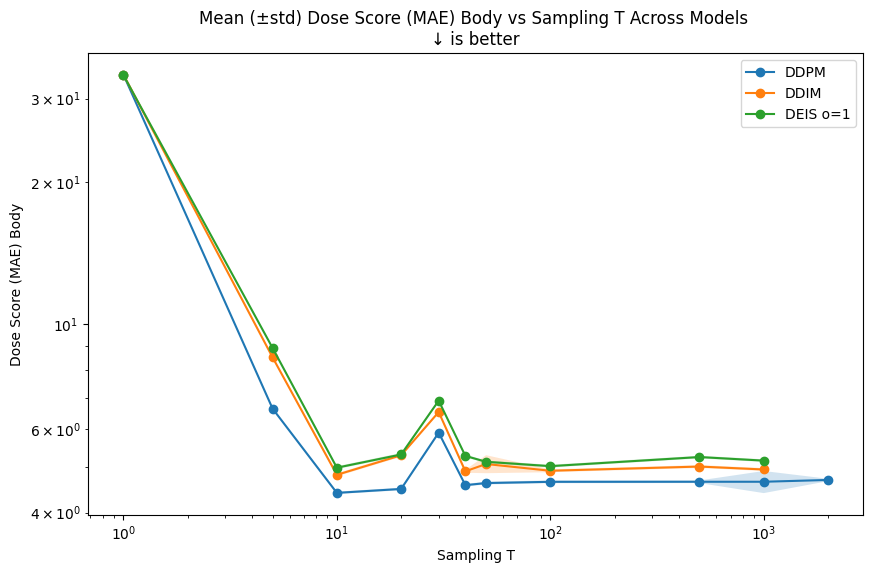

In [46]:
ax = general_comparison.plot_quality_over_T('dose_score_body')
_ = ax.set_yscale('log')
_ = ax.set_xscale('log')

## Final Comparison

In [47]:
selected_comparison = ModelComparison(
  [
    ddpm1000_results,
    ddim1000_results,
    ddpm10_s_results,
    ddpm1_s_results
  ],
  [
    'DDPM T=1000',
    'DDIM T=1000',
    'DDPM Sampling T=10',
    'DDPM Sampling T=1',
  ]
)

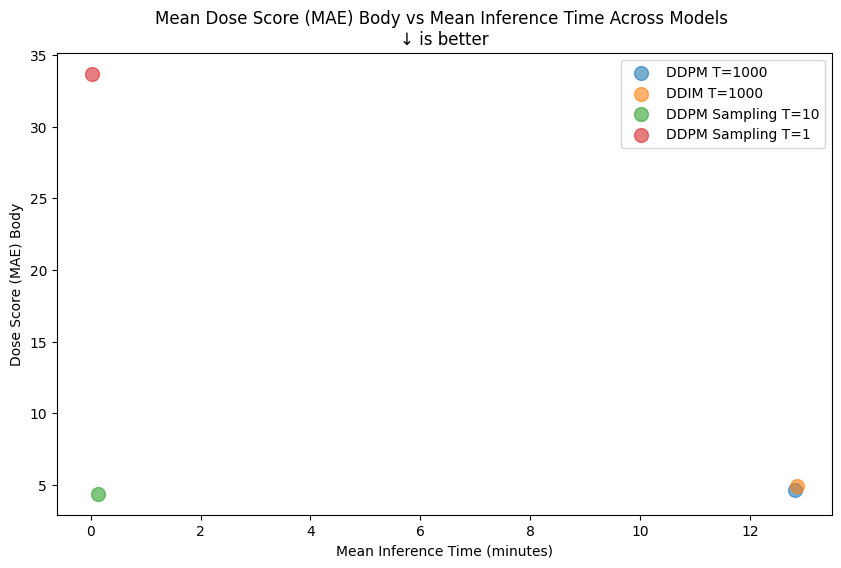

In [48]:
ax = selected_comparison.plot_quality_over_time('dose_score_body')
# _ = ax.set_yscale('log')
# _ = ax.set_xscale('log')